# Лабораторная работа 4. Оценка риска сепсиса
**Цель:** построить воспроизводимую базовую модель для пациентов приёмного покоя и оценить её ошибки с учётом условий задачи.

**Условия:** 200 обращений/сутки, 30 доступных мест; условная цена FP — 20 000 ₽, FN — 500 000 ₽. Положительный класс — `sepsis = 1`.

Задания 1–3 дают базовую модель, но ещё не обосновывают клинический порог запуска лечения. Нельзя считать число найденных случаев числом предотвращённых осложнений: эффект лечения в датасете не измерен.

Пункты 4–6: все преобразования и подбор параметров обучаются только на train; исходное разбиение сохранено.

Пункты 7–9:отдельно обучаем модель, калибровку и политику, проверяем их на прежнем test. Для лимита мест моделируем условные группы по 200 обращений; Выводы не утверждают, что лечение предотвращает все выявленные осложнения.

In [33]:
from pathlib import Path
import io
import base64
import zlib
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, fbeta_score, roc_auc_score, average_precision_score,
    brier_score_loss, log_loss, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.base import clone
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import cross_validate, ParameterGrid
from sklearn.impute import KNNImputer, MissingIndicator
from sklearn.preprocessing import FunctionTransformer
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator


SEED = 42  # Фиксируем случайность для повторяемого разделения и CV.
FP_COST, FN_COST = 20_000, 500_000  # Условные стоимости из задания.
FLOW, CAPACITY = 200, 30
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

## 1. Предобработка данных
### 1.1. Загрузка и аудит
Сначала проверяем схему, типы, дубли, категории и диапазоны. На этом этапе применяем только правила исправления формата и явно некорректных значений. Медианы, масштабирование и отбор по связи с целью будут обучаться после разделения данных.

In [34]:
# Базовый анализ
data_path = Path('lab_4.csv')
raw = pd.read_csv(data_path)
required = ['patient_id','age','sex','admission_source','hours_from_onset',
    'temperature','heart_rate','resp_rate','systolic_bp','spo2','wbc','lactate',
    'crp','creatinine','platelets','glucose','consciousness','immunosuppression',
    'diabetes','ckd','icu_transfer_6h','sepsis']

# Обработка ошибки 
assert set(raw.columns) == set(required), 'Проверьте столбцы исходного файла.'
print('Размер исходной таблицы:', raw.shape)
print('Полные дубли:', raw.duplicated().sum())
print('Повторные patient_id:', raw.patient_id.duplicated().sum())
display(pd.DataFrame({'тип':raw.dtypes.astype(str), 'пропусков':raw.isna().sum(),
                      'уникальных':raw.nunique()}))
display(raw.select_dtypes('number').describe().T.round(2))
display(raw.admission_source.value_counts().rename('число записей').to_frame())

Размер исходной таблицы: (9045, 22)
Полные дубли: 45
Повторные patient_id: 45


,тип,пропусков,уникальных
patient_id,object,0,9000
age,int64,0,80
sex,object,0,2
admission_source,object,0,16
hours_from_onset,float64,0,531
temperature,float64,0,68
heart_rate,float64,0,107
resp_rate,float64,0,25
systolic_bp,float64,0,119
spo2,float64,0,15


,count,mean,std,min,25%,50%,75%,max
age,9045.0,57.86,16.97,18.0,45.00,58.00,70.00,97.00
hours_from_onset,9045.0,15.39,10.34,0.6,7.90,13.10,20.70,88.00
temperature,9045.0,36.52,2.57,0.0,36.00,36.60,37.30,41.40
heart_rate,9045.0,80.18,30.89,42.0,67.00,79.00,91.00,990.00
resp_rate,9045.0,16.32,4.04,8.0,13.00,16.00,19.00,32.00
systolic_bp,9045.0,127.12,19.22,0.0,115.00,127.00,140.00,190.00
spo2,9045.0,96.48,2.35,86.0,95.00,97.00,98.00,100.00
wbc,9045.0,7.71,3.64,1.5,4.90,7.50,10.20,24.00
lactate,8089.0,1.48,0.94,0.2,0.68,1.32,2.12,5.55
crp,9045.0,11.20,14.25,1.0,3.60,7.00,13.30,316.10


,число записей
admission_source,
скорая помощь,2991
самостоятельное обращение,1945
перевод из другого стационара,789
направление поликлиники,756
СМП,544
самообращение,384
Скорая помощь,359
скорая помощь,255
Самостоятельное обращение,249


### 1.2. Дубли, форматы, категории и ошибочные измерения

Всё удаляем или обрабатываем

In [35]:
# Сохраняем исходную таблицу на всякий случай.
df = raw.copy()  
for col in ['patient_id','sex','admission_source']:
    df[col] = df[col].astype('string').str.strip()
df['sex'] = df.sex.str.lower().map({'м':'м','ж':'ж'})
source_map = {
    'скорая помощь':'скорая помощь', 'смп':'скорая помощь',
    'самостоятельное обращение':'самостоятельное обращение',
    'самообращение':'самостоятельное обращение',
    'направление поликлиники':'направление поликлиники',
    'поликлиника':'направление поликлиники',
    'перевод из другого стационара':'перевод из другого стационара',
    'перевод':'перевод из другого стационара'}
df['admission_source'] = df.admission_source.str.lower().map(source_map)
# проверка пропусков и разных случаев с помощью assert
assert df[['sex','admission_source','patient_id']].notna().all().all()
numeric_cols = [c for c in required if c not in ['patient_id','sex','admission_source']]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='raise')
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
assert df.patient_id.is_unique, 'Найдены разные записи одного пациента: нужна проверка или групповой split.'
assert df.sepsis.notna().all() and set(df.sepsis.unique()) == {0,1}
for col in ['immunosuppression','diabetes','ckd','icu_transfer_6h']:
    assert df[col].isin([0,1]).all(), f'Проверьте бинарный столбец {col}'

#введение категорий
bad_masks = {
    'temperature': (df.temperature <= 0),
    'systolic_bp': (df.systolic_bp <= 0),
    'heart_rate': ((df.heart_rate <= 0) | (df.heart_rate > 300))}
quality_log = []
for col, mask in bad_masks.items():
    quality_log.append({'признак':col, 'заменено на NaN':int(mask.sum()),
                        'ошибочные значения':str(sorted(df.loc[mask,col].unique().tolist()))})
    df.loc[mask,col] = np.nan
assert np.isfinite(df[numeric_cols].drop(columns='sepsis').to_numpy()[
    ~np.isnan(df[numeric_cols].drop(columns='sepsis').to_numpy())]).all()
print('Удалено дублей:', before-len(df), '| Осталось пациентов:', len(df))
display(pd.DataFrame(quality_log))
display(df.admission_source.value_counts().to_frame('число пациентов'))
display(df.sepsis.value_counts().sort_index().to_frame('число пациентов'))
print(f'Доля сепсиса: {df.sepsis.mean():.2%}')

Удалено дублей: 45 | Осталось пациентов: 9000


,признак,заменено на NaN,ошибочные значения
0,temperature,38,[0.0]
1,systolic_bp,26,[0.0]
2,heart_rate,14,"[480.0, 510.0, 580.0, 610.0, 710.0, 720.0, 770..."


,число пациентов
admission_source,
скорая помощь,4129
самостоятельное обращение,2734
перевод из другого стационара,1076
направление поликлиники,1061


,число пациентов
sepsis,
0,8312
1,688


Доля сепсиса: 7.64%


### 1.3. Разделение до обучения преобразований
Откладываем 20% пациентов в test с сохранением доли сепсиса. Все решения об отборе и число признаков определяем только на train, используя 5-кратную стратифицированную кросс-валидацию. Test используется для итоговой оценки заранее заданных вариантов.

`patient_id` — технический идентификатор; `icu_transfer_6h` относится к будущему и исключается как утечка цели. Анализы допустимы **только при условии, что результат уже доступен в момент расчёта риска**. Времён назначения и готовности результатов здесь нет; это ограничивает выводы о применимости модели в первые минуты.

In [36]:
# делим датасет и таблица для чтоб посмотреть сколько людей заражены
excluded = ['patient_id','icu_transfer_6h','sepsis']
X = df.drop(columns=excluded)
y = df['sepsis'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.DataFrame({
    'пациентов':[len(y_train),len(y_test)],
    'сепсис':[int(y_train.sum()),int(y_test.sum())],
    'доля сепсиса':[y_train.mean(),y_test.mean()]}, index=['train','test']))

,пациентов,сепсис,доля сепсиса
train,7200,550,0.076389
test,1800,138,0.076667


На train сравниваем частоту сепсиса при наличии и отсутствии результата. Различие показывает, что удаление неполных строк меняет состав оцениваемой популяции. Вероятное объяснение — анализ назначают с учётом тяжести.

Модель будет оцениваться **на всех тестовых пациентах**, включая пациентов без анализов. Для числовых пропусков используем медиану train и индикаторы отсутствия значения. После отбора проверяем, какие индикаторы сохранились. Этот сигнал зависит от правил назначения анализов и может измениться в другой больнице.

In [37]:
missing_rows = []
for col in X_train.columns[X_train.isna().any()]:
    for missing in [False, True]:
        group = X_train[col].isna().eq(missing)
        missing_rows.append({'признак':col, 'значение отсутствует':missing,
            'пациентов':int(group.sum()), 'сепсис':int(y_train.loc[group].sum()),
            'доля сепсиса':y_train.loc[group].mean()})
display(pd.DataFrame(missing_rows).round(4))
complete = X_train.notna().all(axis=1)
display(pd.DataFrame({'выборка':['весь train','только полные строки'],
    'пациентов':[len(y_train),int(complete.sum())],
    'доля сепсиса':[y_train.mean(),y_train.loc[complete].mean()]}).round(4))

,признак,значение отсутствует,пациентов,сепсис,доля сепсиса
0,temperature,False,7175,549,0.0765
1,temperature,True,25,1,0.0400
2,heart_rate,False,7187,546,0.0760
3,heart_rate,True,13,4,0.3077
4,systolic_bp,False,7181,548,0.0763
5,systolic_bp,True,19,2,0.1053
6,lactate,False,6423,542,0.0844
7,lactate,True,777,8,0.0103
8,creatinine,False,6759,516,0.0763
9,creatinine,True,441,34,0.0771


,выборка,пациентов,доля сепсиса
0,весь train,7200,0.0764
1,только полные строки,5981,0.0839


## 2. Отбор признаков
### 2.1. Связи между показателями
Исключаем идентификатор и будущий перевод в реанимацию по смыслу задачи. Затем проверяем корреляции и константные признаки на train.

Naive Bayes предполагает независимость признаков **при фиксированном классе**, поэтому показываем и общую корреляцию Спирмена, и корреляции внутри `sepsis=0` / `sepsis=1`. Нулевая парная корреляция всё равно не доказывает независимость. Не удаляем умеренно коррелирующие показатели автоматически: каждый может содержать дополнительный сигнал. Проверим более короткие наборы по качеству на CV.

,признак 1,признак 2,rho общий,rho sepsis=0,rho sepsis=1
30,temperature,lactate,0.734,0.710,0.862
49,resp_rate,lactate,0.698,0.673,0.854
80,lactate,consciousness,-0.687,-0.659,-0.847
26,temperature,resp_rate,0.673,0.644,0.850
76,lactate,crp,0.668,0.641,0.834
40,heart_rate,lactate,0.664,0.635,0.842
35,temperature,consciousness,-0.656,-0.628,-0.840
70,wbc,lactate,0.650,0.624,0.815
64,spo2,lactate,-0.647,-0.618,-0.828
77,lactate,creatinine,0.644,0.615,0.818


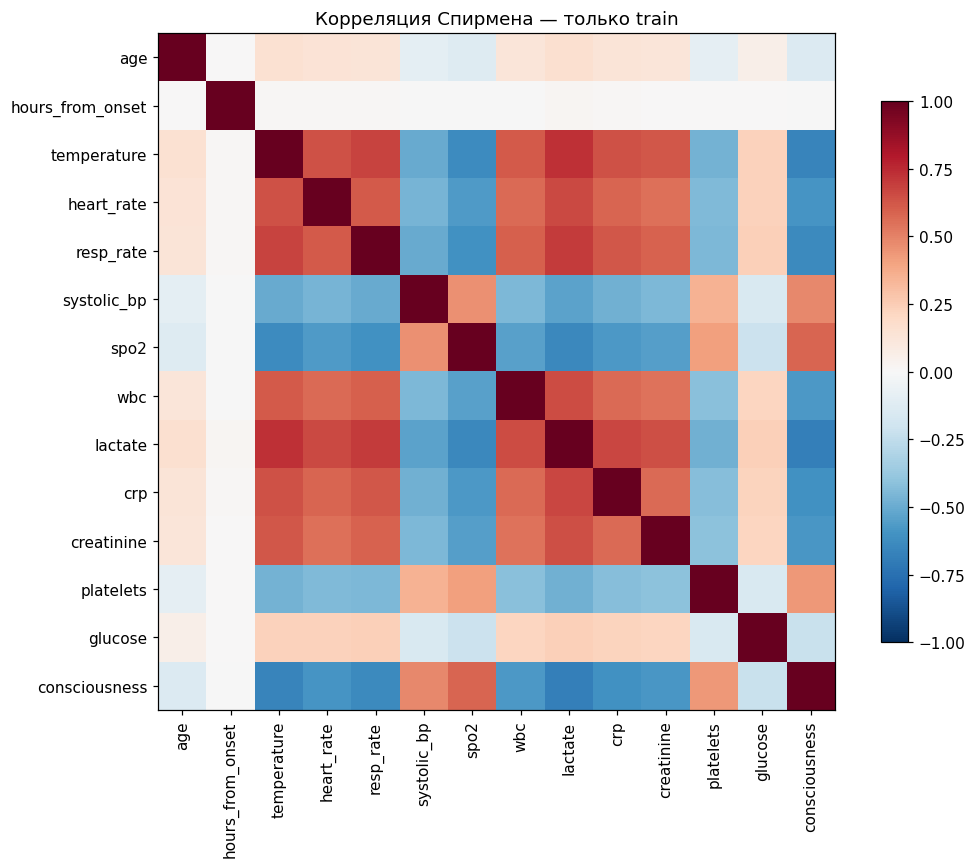

In [38]:
# НАходим корреляции
categorical = ['sex','admission_source']
numeric = [c for c in X_train.columns if c not in categorical]
continuous = [c for c in numeric if c not in ['immunosuppression','diabetes','ckd']]
corr = X_train[continuous].corr(method='spearman')
pairs = []
for i, a in enumerate(continuous):
    for b in continuous[i+1:]:
        pairs.append({'признак 1':a,'признак 2':b,'rho общий':corr.loc[a,b],
            'rho sepsis=0':X_train.loc[y_train==0,[a,b]].corr(method='spearman').iloc[0,1],
            'rho sepsis=1':X_train.loc[y_train==1,[a,b]].corr(method='spearman').iloc[0,1]})
pair_table = pd.DataFrame(pairs).sort_values('rho общий',key=lambda s:s.abs(),ascending=False)
display(pair_table.head(12).round(3))
fig, ax = plt.subplots(figsize=(10,8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(continuous)),continuous,rotation=90)
ax.set_yticks(range(len(continuous)),continuous)
ax.set_title('Корреляция Спирмена — только train')
fig.colorbar(im,ax=ax,shrink=.8)
plt.tight_layout()
plt.show()

### 2.2. Обработка и статистический отбор внутри Pipeline

1. Числовые признаки: медиана и индикаторы пропусков, затем стандартизация.
2. Категории: наиболее частое значение и One-Hot Encoding (`drop='first'` сокращает избыточность).
3. `VarianceThreshold` удаляет константные столбцы за ненадобностью.
4. `SelectKBest(f_classif)` ранжирует признаки по различию между классами. Это простой фильтр, а не доказательство причинного влияния. Его F-оценки используем для ранжирования, не для проверки клинических гипотез.
5. Сравниваем `k=5, 10, 15, all` на 5 фолдах train по Average Precision (AP). Выбираем наибольшую среднюю AP; test не участвует.

**Упрощение baseline:** GaussianNB предполагает нормальность каждого признака внутри класса. Бинарные признаки, индикаторы пропусков и One-Hot-столбцы этому предположению не соответствуют; медианная импутация также создаёт точечную массу. Мы явно принимаем это приближение для стандартной базовой модели. Более строгий вариант — смешанный Naive Bayes с Gaussian/Bernoulli/Categorical распределениями

In [39]:
# трансформеры, пайплайны, всё здесь
num_pipe = Pipeline([
    ('imputer',SimpleImputer(strategy='median',add_indicator=True)),
    ('scaler',StandardScaler())])
cat_pipe = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False))])
preprocess = ColumnTransformer([
    ('num',num_pipe,numeric),('cat',cat_pipe,categorical)],verbose_feature_names_out=True)
pipeline = Pipeline([
    ('preprocess',preprocess),
    ('constant_filter',VarianceThreshold()), # Константа везде константа или не везде
    ('selection',SelectKBest(score_func=f_classif,k='all')),
    ('nb',GaussianNB())])
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
search = GridSearchCV(pipeline,{'selection__k':[5,10,15,'all']},
    scoring='average_precision',cv=cv,refit=True,n_jobs=1,error_score='raise')
search.fit(X_train,y_train)  # Все преобразования заново обучаются внутри каждого фолда.
cv_table = pd.DataFrame(search.cv_results_)[[
    'param_selection__k','mean_test_score','std_test_score','rank_test_score']]
cv_table.columns = ['k','AP mean CV','AP std CV','место']
display(cv_table.sort_values('место').round(4))
model = search.best_estimator_  # Уже переобучен на всём train, test ещё не использовался.
print('Выбрано:', search.best_params_)

names = model.named_steps['preprocess'].get_feature_names_out()
nonconstant = model.named_steps['constant_filter'].get_support()
valid_names = names[nonconstant]
selector = model.named_steps['selection']
selection_table = pd.DataFrame({'признак':valid_names,
    'F score':selector.scores_,'оставлен':selector.get_support()})
display(selection_table.sort_values('F score',ascending=False).round(3))
print('Удалены константы:', names[~nonconstant].tolist())
print('Итоговое число признаков:', int(selector.get_support().sum()))
print('Оставлены индикаторы:', [n for n in valid_names[selector.get_support()] if 'missingindicator' in n])

,k,AP mean CV,AP std CV,место
2,15,0.2841,0.0207,1
3,all,0.2698,0.0124,2
1,10,0.2638,0.0200,3
0,5,0.2477,0.0215,4


Выбрано: {'selection__k': 15}


,признак,F score,оставлен
13,num__consciousness,316.826,True
9,num__crp,210.781,True
8,num__lactate,205.016,True
6,num__spo2,101.236,True
10,num__creatinine,96.694,True
7,num__wbc,95.190,True
4,num__resp_rate,66.147,True
3,num__heart_rate,63.474,True
20,num__missingindicator_lactate,54.319,True
0,num__age,51.365,True


Удалены константы: []
Итоговое число признаков: 15
Оставлены индикаторы: ['num__missingindicator_lactate']


## 3. Naive Bayes: базовая модель и метрики на test
### 3.1. Протокол оценки

**Основная метрика отбора — Average Precision (AP):** оценивает ранжирование положительного класса с учётом precision и recall, что полезно при редком сепсисе. Это ступенчатое усреднение precision по приростам recall, а не трапецеидальная площадь PR-кривой. Дополнительно оцениваем ROC-AUC.

**Для решений:** recall (сколько случаев найдено), precision (какая часть тревог верна), specificity, F1, F2, balanced accuracy и матрица ошибок. Accuracy приводим для полноты: при редком сепсисе высокая accuracy возможна даже у бесполезного правила «всем 0».

**Для вероятностей:** Brier score, log loss и калибровочная кривая. ROC-AUC/AP не измеряют достоверность численных вероятностей.

Порог **0,5 — только стандартная точка отсчёта**, а не обоснованный клинический порог. Он соответствует равным стоимостям ошибок лишь при корректных вероятностях и отсутствии ограничений. Балансировку классов не применяем: искусственное изменение частоты сепсиса изменило бы априорные вероятности baseline.

In [40]:
# Dummy нужен только как статистический ориентир: действующее правило врача не задано.
dummy = DummyClassifier(strategy='prior').fit(X_train,y_train)
p_dummy = dummy.predict_proba(X_test)[:,1]
p_test = model.predict_proba(X_test)[:,1]
assert np.isfinite(p_test).all() and ((p_test>=0)&(p_test<=1)).all()

def evaluate(y_true, probability, decision=None):
    y_true = np.asarray(y_true)
    decision = (probability >= 0.5).astype(int) if decision is None else np.asarray(decision)
    tn,fp,fn,tp = confusion_matrix(y_true,decision,labels=[0,1]).ravel()
    return {'Accuracy':accuracy_score(y_true,decision),
        'Balanced accuracy':balanced_accuracy_score(y_true,decision),
        'Precision':precision_score(y_true,decision,zero_division=0),
        'Recall':recall_score(y_true,decision,zero_division=0),
        'Specificity':tn/(tn+fp), 'F1':f1_score(y_true,decision,zero_division=0),
        'F2':fbeta_score(y_true,decision,beta=2,zero_division=0),
        'ROC-AUC':roc_auc_score(y_true,probability),
        'AP':average_precision_score(y_true,probability),
        'Brier':brier_score_loss(y_true,probability),
        'Log loss':log_loss(y_true,probability,labels=[0,1]),
        'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
        'Тревог':int(tp+fp),'Доля тревог':(tp+fp)/len(y_true),
        'Условная стоимость, ₽':int(FP_COST*fp+FN_COST*fn)}

metrics = pd.DataFrame({
    'Dummy: всем 0':evaluate(y_test,p_dummy),
    'GaussianNB: порог 0.5':evaluate(y_test,p_test)}).T
display(metrics.round(4))
print('AP постоянного прогноза равна доле сепсиса в test:', round(y_test.mean(),4))

,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,ROC-AUC,AP,Brier,Log loss,TN,FP,FN,TP,Тревог,Доля тревог,"Условная стоимость, ₽"
Dummy: всем 0,0.9233,0.5000,0.0000,0.0000,1.0000,0.0000,0.0000,0.5000,0.0767,0.0708,0.2706,1662.0,0.0,138.0,0.0,0.0,0.0000,69000000.0
GaussianNB: порог 0.5,0.8417,0.6319,0.2095,0.3841,0.8797,0.2711,0.3292,0.6959,0.2364,0.1450,0.9863,1462.0,200.0,85.0,53.0,253.0,0.1406,46500000.0


AP постоянного прогноза равна доле сепсиса в test: 0.0767


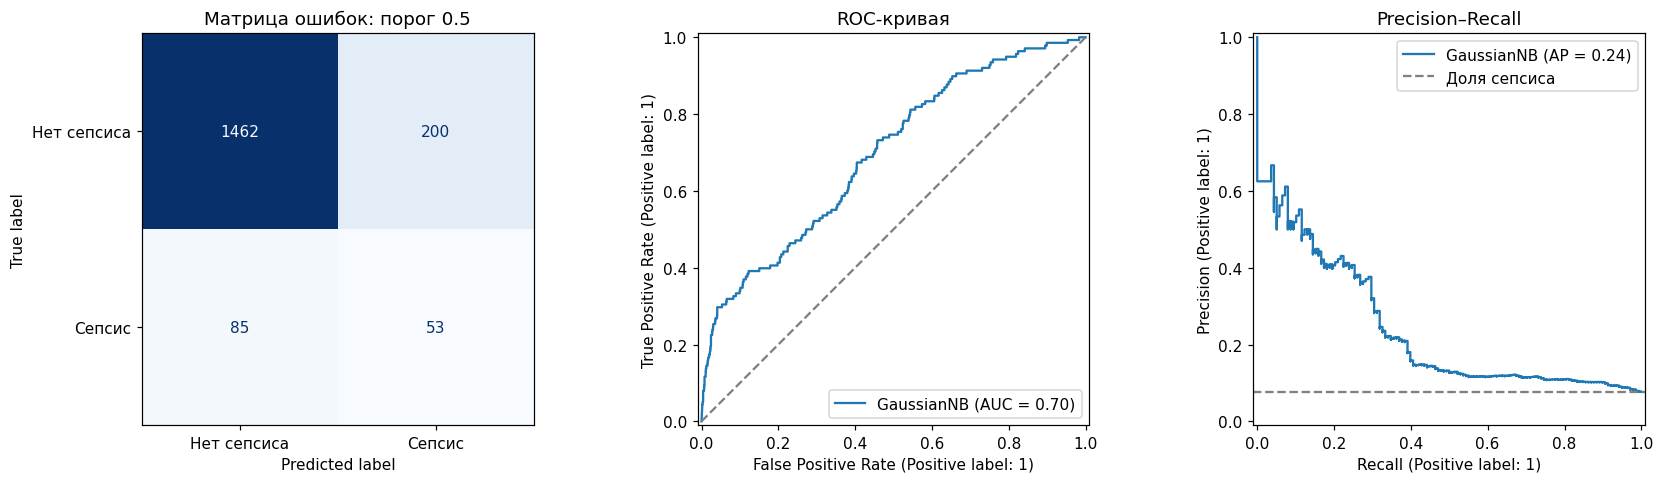

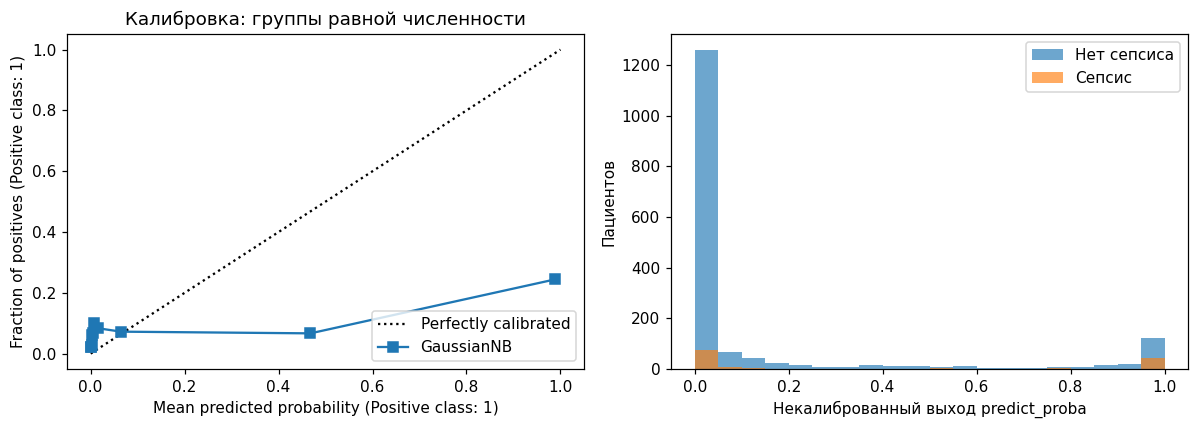

In [41]:
# Визуал всего выше
fig, axes = plt.subplots(1,3,figsize=(16,4.5))
ConfusionMatrixDisplay.from_predictions(y_test,p_test>=.5,display_labels=['Нет сепсиса','Сепсис'],
    ax=axes[0],colorbar=False,cmap='Blues')
axes[0].set_title('Матрица ошибок: порог 0.5')
RocCurveDisplay.from_predictions(y_test,p_test,ax=axes[1],name='GaussianNB')
axes[1].plot([0,1],[0,1],'--',color='gray')
axes[1].set_title('ROC-кривая')
PrecisionRecallDisplay.from_predictions(y_test,p_test,ax=axes[2],name='GaussianNB')
axes[2].axhline(y_test.mean(),linestyle='--',color='gray',label='Доля сепсиса')
axes[2].set_title('Precision–Recall')
axes[2].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1,2,figsize=(11,4))
CalibrationDisplay.from_predictions(y_test,p_test,n_bins=10,strategy='quantile',
    ax=axes[0],name='GaussianNB')
axes[0].set_title('Калибровка: группы равной численности')
axes[1].hist(p_test[y_test.to_numpy()==0],bins=20,alpha=.65,label='Нет сепсиса')
axes[1].hist(p_test[y_test.to_numpy()==1],bins=20,alpha=.65,label='Сепсис')
axes[1].set_xlabel('Некалиброванный выход predict_proba')
axes[1].set_ylabel('Пациентов')
axes[1].legend()
plt.tight_layout()
plt.show()

### 3.2. Устойчивость оценки и пациенты без анализов
Для ключевых метрик приводим 95% bootstrap-интервалы. Это неопределённость на данном test при фиксированной обученной модели; она не включает вариацию повторного обучения и перенос в другую больницу. В подгруппах с малым числом случаев recall особенно нестабилен.

In [42]:
# Подключаем метрики
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
bootstrap = []
for _ in range(1000):
    idx = rng.integers(0,len(yt),len(yt))
    if np.unique(yt[idx]).size < 2:
        continue
    bootstrap.append([roc_auc_score(yt[idx],p_test[idx]),
        average_precision_score(yt[idx],p_test[idx]),
        recall_score(yt[idx],p_test[idx]>=.5,zero_division=0)])
ci = np.quantile(np.asarray(bootstrap),[.025,.975],axis=0)
display(pd.DataFrame({'метрика':['ROC-AUC','AP','Recall при 0.5'],
    'оценка':[roc_auc_score(yt,p_test),average_precision_score(yt,p_test),recall_score(yt,p_test>=.5)],
    '95% нижняя':ci[0], '95% верхняя':ci[1]}).round(4))

subgroup_rows = []
for col in ['lactate','creatinine']:
    for absent in [False,True]:
        mask = X_test[col].isna().eq(absent).to_numpy()
        subgroup_rows.append({'анализ':col,'отсутствует':absent,'n':int(mask.sum()),
            'сепсис':int(yt[mask].sum()),'доля сепсиса':yt[mask].mean(),
            'recall':recall_score(yt[mask],p_test[mask]>=.5,zero_division=0),
            'Brier':brier_score_loss(yt[mask],p_test[mask])})
display(pd.DataFrame(subgroup_rows).round(4))

,метрика,оценка,95% нижняя,95% верхняя
0,ROC-AUC,0.6959,0.6488,0.7408
1,AP,0.2364,0.1713,0.3198
2,Recall при 0.5,0.3841,0.3030,0.4741


,анализ,отсутствует,n,сепсис,доля сепсиса,recall,Brier
0,lactate,False,1629,135,0.0829,0.3926,0.1584
1,lactate,True,171,3,0.0175,0.0000,0.0175
2,creatinine,False,1687,134,0.0794,0.3731,0.1453
3,creatinine,True,113,4,0.0354,0.7500,0.1407


### 3.3. Предварительный перевод результата в условия отделения

По заданной матрице потерь: стоимость действия для пациента с риском p — `(1−p) × 20 000`; стоимость бездействия — `p × 500 000`. При равенстве получаем:

**p\* = 20 000 / (20 000 + 500 000) ≈ 3,85%.**

Это теоретический порог только для **калиброванной вероятности**, нулевых дополнительных потерь правильных решений и отсутствия ограничения мест. Применять 3,85% непосредственно к необработанному выходу GaussianNB как готовую рекомендацию нельзя.

Вместимость составляет 30/200 = **15% потока**. Поэтому дополнительно оцениваем `precision@15%` и `recall@15%`: ретроспективно выбираем 15% тестовых пациентов с самым высоким баллом. При равенстве баллов используем фиксированный `patient_id`, а не истинную метку. Это оценка ранжирования; границу балла не оптимизируем по ответам.

**Ограничение:** в данных нет дат и последовательности поступления. Верхние 15% всей тестовой выборки — только приближение ресурса, а не доказанная способность соблюдать лимит 30 мест в каждые сутки. Просмотр всех пациентов дня заранее невозможен; для реального процесса нужны временная проверка, правила очереди и клинический приоритет. Запуск протокола и занятие койки также не обязательно одно действие — здесь их приравниваем только для расчёта по условию.

In [43]:
# смотрим метрики модели
economic_threshold = FP_COST/(FP_COST+FN_COST)
print(f'Теоретический порог для калиброванного риска: {economic_threshold:.2%}')
k_capacity = math.floor(len(y_test)*CAPACITY/FLOW)
ranking = pd.DataFrame({'score':p_test,
    'patient_id':df.loc[X_test.index,'patient_id'].to_numpy(),
    'position':np.arange(len(y_test))}).sort_values(
        ['score','patient_id'],ascending=[False,True],kind='mergesort')
top_decision = np.zeros(len(y_test),dtype=int)
top_decision[ranking.head(k_capacity).position.to_numpy()] = 1
top_metrics = evaluate(y_test,p_test,top_decision)
policy_table = pd.concat([metrics,pd.DataFrame([top_metrics],index=['GaussianNB: верхние 15%'])])
display(policy_table[['Recall','Precision','TP','FP','FN','TN','Тревог',
    'Доля тревог','Условная стоимость, ₽']].round(4))
daily = policy_table[['Тревог','TP','FP','FN','Условная стоимость, ₽']]*FLOW/len(y_test)
daily.columns = ['тревог/сутки','верно выявленных/сутки','ложных тревог/сутки',
                 'пропущенных/сутки','условные потери ₽/сутки']
display(daily.round(2))
print('Пересчёт на сутки предполагает такой же состав потока, как в test.')
print('Условные потери учитывают только FP и FN из задания, а не полную экономику лечения.')

Теоретический порог для калиброванного риска: 3.85%


,Recall,Precision,TP,FP,FN,TN,Тревог,Доля тревог,"Условная стоимость, ₽"
Dummy: всем 0,0.0000,0.0000,0.0,0.0,138.0,1662.0,0.0,0.0000,69000000.0
GaussianNB: порог 0.5,0.3841,0.2095,53.0,200.0,85.0,1462.0,253.0,0.1406,46500000.0
GaussianNB: верхние 15%,0.3913,0.2000,54.0,216.0,84.0,1446.0,270.0,0.1500,46320000.0


,тревог/сутки,верно выявленных/сутки,ложных тревог/сутки,пропущенных/сутки,условные потери ₽/сутки
Dummy: всем 0,0.00,0.00,0.00,15.33,7666666.67
GaussianNB: порог 0.5,28.11,5.89,22.22,9.44,5166666.67
GaussianNB: верхние 15%,30.00,6.00,24.00,9.33,5146666.67


Пересчёт на сутки предполагает такой же состав потока, как в test.
Условные потери учитывают только FP и FN из задания, а не полную экономику лечения.


## 4. Метод опорных векторов: подготовка и сравнение с Naive Bayes

SVM ищет разделяющую границу с большим зазором между классами. Ядро позволяет строить нелинейную границу; независимость признаков не требуется. Поэтому взаимосвязь давления, пульса и дыхания сама по себе не нарушает предпосылки метода.

**Подготовка:** используем очищенные train/test, исключаем `patient_id` и `icu_transfer_6h`. Числовые пропуски заполняем медианами train, добавляем индикаторы, стандартизируем числовые признаки и индикаторы; категории кодируем One-Hot. Константные столбцы удаляем. Все действия — внутри Pipeline. Для SVM масштаб влияет на расстояния и значение ядра: высокий численный диапазон креатинина не должен автоматически давать ему больший вес, чем лактату.

Набор из 15 признаков был выбран под Naive Bayes. Для SVM оставляем все допустимые признаки после удаления констант: чужой отбор может убрать полезные взаимодействия. Для более чистого сравнения дополнительно обучаем GaussianNB на **точно такой же матрице признаков**, как SVM. Это отделяет сравнение алгоритмов от различия наборов признаков.

Базовый SVM: RBF, `C=1`, `gamma='scale'`, исходные частоты классов (`class_weight=None`). Эти настройки — точка отсчёта; подбор идёт в пункте 5.

**Выход SVM — `decision_function`, а не вероятность сепсиса.** ROC-AUC и AP допускают такие баллы. Стандартная граница `score=0` дана только для справочных метрик классификации и не обоснована ценами ошибок. Для основного сопоставления используем AP, ROC-AUC и одинаковую долю приоритетных пациентов — верхние 15%. Числа 0 у SVM и 0,5 у NB нельзя сравнивать как уровни риска. Brier/log loss для некалиброванного SVM не рассчитываем; преобразование баллов сигмоидой без обучения не решает вопрос калибровки.

In [44]:
def top_fraction(score, index, fraction=CAPACITY/FLOW):
    # Лимит выбирается по условию задачи, без использования истинных меток.
    k = math.floor(len(score)*fraction)
    order = pd.DataFrame({'score':np.asarray(score),
        'id':df.loc[index,'patient_id'].to_numpy(),
        'position':np.arange(len(score))}).sort_values(
            ['score','id'],ascending=[False,True],kind='mergesort')
    decision = np.zeros(len(score),dtype=int)
    decision[order.head(k).position.to_numpy()] = 1
    return decision

def score_metrics(y_true, score, decision):
    # Вероятностные метрики здесь намеренно отсутствуют: score может быть SVM-margin.
    tn,fp,fn,tp = confusion_matrix(y_true,decision,labels=[0,1]).ravel()
    return {'ROC-AUC':roc_auc_score(y_true,score),
        'AP':average_precision_score(y_true,score),
        'Accuracy':accuracy_score(y_true,decision),
        'Balanced accuracy':balanced_accuracy_score(y_true,decision),
        'Precision':precision_score(y_true,decision,zero_division=0),
        'Recall':recall_score(y_true,decision,zero_division=0),
        'Specificity':tn/(tn+fp), 'F1':f1_score(y_true,decision,zero_division=0),
        'F2':fbeta_score(y_true,decision,beta=2,zero_division=0),
        'TP':int(tp),'FP':int(fp),'FN':int(fn),'TN':int(tn),
        'Тревог':int(tp+fp),'Условные потери ₽':int(FP_COST*fp+FN_COST*fn)}

svm_base = Pipeline([
    ('preprocess',clone(preprocess)),('constant_filter',VarianceThreshold()),
    ('svc',SVC(kernel='rbf',C=1,gamma='scale',class_weight=None,
               cache_size=256,random_state=SEED))])
svm_base.fit(X_train,y_train)
nb_same_features = Pipeline([
    ('preprocess',clone(preprocess)),('constant_filter',VarianceThreshold()),
    ('nb',GaussianNB())]).fit(X_train,y_train)
svm_base_score = svm_base.decision_function(X_test)
nb_same_score = nb_same_features.predict_proba(X_test)[:,1]
models_scores = {'NB: отобранные признаки':p_test,
    'NB: те же признаки, что SVM':nb_same_score,
    'SVM: базовый RBF':svm_base_score}
default_decisions = {'NB: отобранные признаки':p_test>=.5,
    'NB: те же признаки, что SVM':nb_same_score>=.5,
    'SVM: базовый RBF':svm_base.predict(X_test)}
standard_comparison = pd.DataFrame({name:score_metrics(y_test,score,default_decisions[name])
    for name,score in models_scores.items()}).T
resource_comparison = pd.DataFrame({name:score_metrics(y_test,score,top_fraction(score,X_test.index))
    for name,score in models_scores.items()}).T
print('Справочно: стандартные границы моделей (не клинические пороги)')
display(standard_comparison.round(4))
print('Сопоставимая нагрузка: верхние 15% одних и тех же тестовых пациентов')
display(resource_comparison.round(4))

Справочно: стандартные границы моделей (не клинические пороги)


,ROC-AUC,AP,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,TP,FP,FN,TN,Тревог,Условные потери ₽
NB: отобранные признаки,0.6959,0.2364,0.8417,0.6319,0.2095,0.3841,0.8797,0.2711,0.3292,53.0,200.0,85.0,1462.0,253.0,46500000.0
"NB: те же признаки, что SVM",0.6797,0.2000,0.8467,0.6146,0.2026,0.3406,0.8887,0.2541,0.2997,47.0,185.0,91.0,1477.0,232.0,49200000.0
SVM: базовый RBF,0.7692,0.3209,0.9267,0.5483,0.6364,0.1014,0.9952,0.1750,0.1220,14.0,8.0,124.0,1654.0,22.0,62160000.0


Сопоставимая нагрузка: верхние 15% одних и тех же тестовых пациентов


,ROC-AUC,AP,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,TP,FP,FN,TN,Тревог,Условные потери ₽
NB: отобранные признаки,0.6959,0.2364,0.8333,0.6307,0.2000,0.3913,0.8700,0.2647,0.3285,54.0,216.0,84.0,1446.0,270.0,46320000.0
"NB: те же признаки, что SVM",0.6797,0.2000,0.8311,0.6228,0.1926,0.3768,0.8688,0.2549,0.3163,52.0,218.0,86.0,1444.0,270.0,47360000.0
SVM: базовый RBF,0.7692,0.3209,0.8467,0.6778,0.2444,0.4783,0.8773,0.3235,0.4015,66.0,204.0,72.0,1458.0,270.0,40080000.0


## 5. Подбор ядра и параметров по кросс-валидации

Используем **только 7200 пациентов train** и те же 5 стратифицированных фолдов. Критерий выбора — средняя AP. Для контроля также сохраняем ROC-AUC и длительность обучения.

| Ядро | Параметры в сетке | Смысл |
|---|---|---|
| linear (LinearSVC) | C: 0,1; 1; 10 | Линейная граница; C регулирует штраф за ошибки и нарушения зазора |
| RBF | C: 0,1; 1; 10; gamma: scale; 0,01; 0,1 | gamma задаёт локальность влияния: больше gamma — более локальная и гибкая граница |
| poly | C: 0,1; 1; degree: 2; 3; coef0: 0; 1; gamma: scale | Степень и смещение полиномиального ядра; gamma фиксирована правилом scale |

Всего 20 комбинаций × 5 фолдов = 100 обучений, затем refit лучшего варианта на всём train. Все импутеры и масштабы заново обучаются внутри фолдов. `gamma='scale'` вычисляется по преобразованному обучающему набору каждого фолда. Сетка ограниченная: её победитель — лучший среди проверенных вариантов, не глобальный оптимум.

Test не выбирает ядро, C или gamma. Средняя CV победителя используется для выбора и может быть оптимистичной; это не независимая оценка. Test уже использовался в первой части работы: новые варианты заданы до просмотра их тестовых результатов, но для окончательного внедрения всё равно нужна новая временная выборка.

**Вычислительный выбор:** линейный вариант обучаем через `LinearSVC(dual="auto")`, а RBF и poly через `SVC`. LinearSVC использует другую функцию потерь (squared hinge) и иначе регуляризует свободный член; это сравнение стандартных реализаций линейного и нелинейного SVM, а не исключительно замена ядра в одном решателе. Такой выбор ускоряет линейный вариант при небольшом числе признаков относительно числа пациентов. Для всех вариантов одинаковы train/test, фолды, подготовка признаков и критерий AP.

Число комбинаций: 20
Fitting 5 folds for each of 20 candidates, totalling 100 fits


,params,mean_test_AP,std_test_AP,mean_test_ROC_AUC,mean_fit_time,rank_test_AP
10,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3820,0.0341,0.7668,0.4750,1
7,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3760,0.0318,0.7556,0.3742,2
6,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3727,0.0280,0.7569,0.4851,3
15,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3720,0.0328,0.7524,0.3037,4
4,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3706,0.0329,0.7528,0.3410,5
3,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3678,0.0317,0.7565,0.4371,6
18,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3663,0.0358,0.7547,0.3589,7
14,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3618,0.0314,0.7557,0.2569,8
12,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3612,0.0380,0.7787,0.2443,9
16,"{'svc': SVC(cache_size=256, random_state=42), ...",0.3584,0.0423,0.7661,0.3035,10


Победитель CV: {'svc': SVC(cache_size=256, random_state=42), 'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Средняя AP CV: 0.382
Стандартные границы, только диагностическое сравнение:


,ROC-AUC,AP,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,TP,FP,FN,TN,Тревог,Условные потери ₽
NB: отобранные признаки,0.6959,0.2364,0.8417,0.6319,0.2095,0.3841,0.8797,0.2711,0.3292,53.0,200.0,85.0,1462.0,253.0,46500000.0
"NB: те же признаки, что SVM",0.6797,0.2000,0.8467,0.6146,0.2026,0.3406,0.8887,0.2541,0.2997,47.0,185.0,91.0,1477.0,232.0,49200000.0
SVM: базовый RBF,0.7692,0.3209,0.9267,0.5483,0.6364,0.1014,0.9952,0.1750,0.1220,14.0,8.0,124.0,1654.0,22.0,62160000.0
SVM: подбор по CV,0.7529,0.3132,0.9278,0.5556,0.6667,0.1159,0.9952,0.1975,0.1389,16.0,8.0,122.0,1654.0,24.0,61160000.0


Одинаковый ресурс: верхние 15%:


,ROC-AUC,AP,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,TP,FP,FN,TN,Тревог,Условные потери ₽
NB: отобранные признаки,0.6959,0.2364,0.8333,0.6307,0.2000,0.3913,0.8700,0.2647,0.3285,54.0,216.0,84.0,1446.0,270.0,46320000.0
"NB: те же признаки, что SVM",0.6797,0.2000,0.8311,0.6228,0.1926,0.3768,0.8688,0.2549,0.3163,52.0,218.0,86.0,1444.0,270.0,47360000.0
SVM: базовый RBF,0.7692,0.3209,0.8467,0.6778,0.2444,0.4783,0.8773,0.3235,0.4015,66.0,204.0,72.0,1458.0,270.0,40080000.0
SVM: подбор по CV,0.7529,0.3132,0.8500,0.6895,0.2556,0.5000,0.8791,0.3382,0.4197,69.0,201.0,69.0,1461.0,270.0,38520000.0


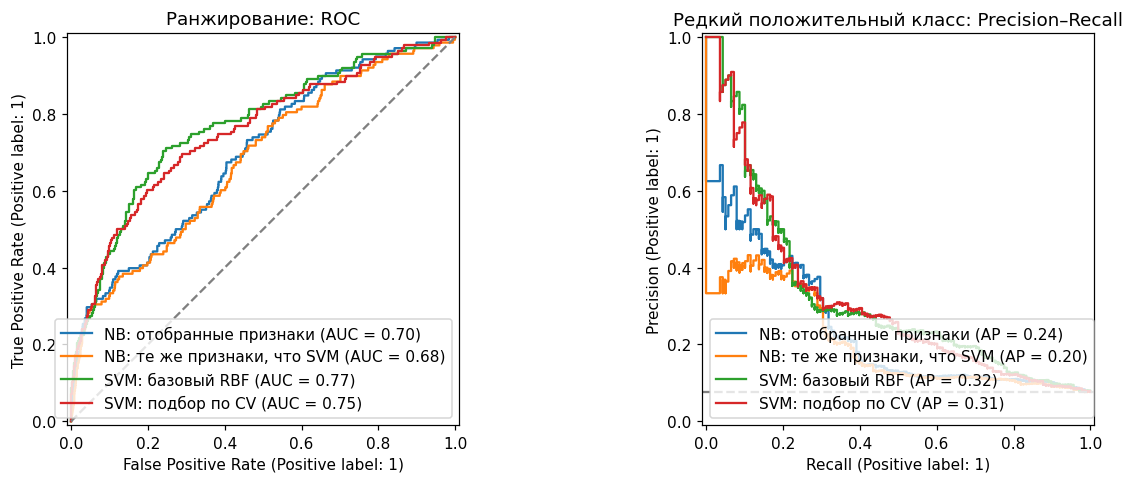

In [45]:
# реализация того, что написано сверху
svm_grid = [
    {'svc':[LinearSVC(dual='auto',max_iter=20000,random_state=SEED)],'svc__C':[.1,1,10]},
    {'svc':[SVC(cache_size=256,random_state=SEED)],'svc__kernel':['rbf'],'svc__C':[.1,1,10],'svc__gamma':['scale',.01,.1]},
    {'svc':[SVC(cache_size=256,random_state=SEED)],'svc__kernel':['poly'],'svc__C':[.1,1],'svc__degree':[2,3],
     'svc__gamma':['scale'],'svc__coef0':[0,1]}]
print('Число комбинаций:',len(list(ParameterGrid(svm_grid))))
svm_search = GridSearchCV(clone(svm_base),svm_grid,
    scoring={'AP':'average_precision','ROC_AUC':'roc_auc'},refit='AP',
    cv=cv,n_jobs=2,error_score='raise',return_train_score=False,verbose=2)
svm_search.fit(X_train,y_train)
svm_best = svm_search.best_estimator_
svm_cv_table = pd.DataFrame(svm_search.cv_results_)
display(svm_cv_table[['params','mean_test_AP','std_test_AP','mean_test_ROC_AUC',
    'mean_fit_time','rank_test_AP']].sort_values('rank_test_AP').round(4))
print('Победитель CV:',svm_search.best_params_)
print('Средняя AP CV:',round(svm_search.best_score_,4))
svm_best_score = svm_best.decision_function(X_test)
models_scores['SVM: подбор по CV'] = svm_best_score
default_decisions['SVM: подбор по CV'] = svm_best.predict(X_test)
standard_comparison = pd.DataFrame({name:score_metrics(y_test,score,default_decisions[name])
    for name,score in models_scores.items()}).T
resource_comparison = pd.DataFrame({name:score_metrics(y_test,score,top_fraction(score,X_test.index))
    for name,score in models_scores.items()}).T
print('Стандартные границы, только диагностическое сравнение:')
display(standard_comparison.round(4))
print('Одинаковый ресурс: верхние 15%:')
display(resource_comparison.round(4))

fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for name,score in models_scores.items():
    RocCurveDisplay.from_predictions(y_test,score,ax=axes[0],name=name)
    PrecisionRecallDisplay.from_predictions(y_test,score,ax=axes[1],name=name)
axes[0].plot([0,1],[0,1],'--',color='gray')
axes[0].set_title('Ранжирование: ROC')
axes[1].axhline(y_test.mean(),color='gray',linestyle='--')
axes[1].set_title('Редкий положительный класс: Precision–Recall')
plt.tight_layout()
plt.show()

## 6. Пропущенные анализы: четыре способа обработки лактата

Сравниваем четыре заранее заданных способа, сохраняя всех пациентов и меняя **только обработку лактата**. Для остальных числовых признаков остаются медиана + индикатор пропуска + стандартизация; кодирование категорий одинаковое. Ядро и параметры SVM фиксируем по пункту 5. Таким образом сравниваем стратегии при одном алгоритме, а не смесь разных моделей и правил заполнения.

| Способ | Что делаем | Что проверяем |
|---|---|---|
| Медиана | Пропуск лактата заменяем медианой train, без индикатора | Простая отправная точка; причина отсутствия теряется |
| Медиана + индикатор | Та же медиана и отдельный признак отсутствия | Добавляет сигнал о процессе назначения анализа |
| KNN + индикатор | Заполняем лактат по 5 ближайшим пациентам train; сохраняем индикатор | Используем другие показатели, чтобы получить индивидуальную оценку |
| Без лактата | Удаляем и значение лактата, и его индикатор | Может ли модель обходиться без этого анализа вообще |

KNN ищет соседей по доступным числовым признакам после стандартизации; целевая переменная не участвует. Используем `nan_euclidean` и взвешивание по расстоянию. Кандидаты в соседи берутся только из train текущего фолда. Восстановленные KNN значения других столбцов не попадают в итоговую матрицу: из этой ветки берём только лактат. Важно масштабировать **до поиска соседей**, а не только после заполнения.

Сначала сравниваем AP на тех же фолдах train и фиксируем победителя. Затем показываем результаты всех заранее заданных способов на общем test, включая подгруппы с лактатом и без него. Изменять выбранный способ по тестовой таблице нельзя. Последовательный подбор ядра и способа заполнения на тех же фолдах не является nested CV; оценка CV здесь служит выбору настроек, а не доказательству обобщения.

**Почему не удаляем неполные строки:** это оставит за пределами обслуживания пациентов без анализа и изменит долю сепсиса. Ниже отдельно показываем покрытие и состав такой выборки. Оценку только на измеренном лактате нельзя напрямую сравнивать с оценкой на всех обращениях. По одним наблюдаемым данным также нельзя узнать ошибку восстановления истинного лактата там, где он не был измерен; сравнивается качество прогноза сепсиса.

In [46]:
# посмотрим какие способы лучше себя покажут
other_numeric = [c for c in numeric if c!='lactate']
lactate_position = numeric.index('lactate')

def take_lactate_column(array):
    # Сохраняем двумерный формат, который требуется ColumnTransformer.
    return np.asarray(array)[:,[lactate_position]]

def make_lactate_preprocess(method):
    branches = [
        ('other_numeric',Pipeline([
            ('imputer',SimpleImputer(strategy='median',add_indicator=True)),
            ('scale',StandardScaler())]),other_numeric),
        ('categories',clone(cat_pipe),categorical)]
    if method in ['median','median_indicator']:
        branches.append(('lactate',Pipeline([
            ('imputer',SimpleImputer(strategy='median',add_indicator=False)),
            ('scale',StandardScaler())]),['lactate']))
    elif method=='knn_indicator':
        branches.append(('lactate',Pipeline([
            ('scale_for_distance',StandardScaler()),  # Сохраняет NaN, fit только на train.
            ('knn',KNNImputer(n_neighbors=5,weights='distance',metric='nan_euclidean')),
            ('take_lactate',FunctionTransformer(take_lactate_column)),
            ('scale_output',StandardScaler())]),numeric))
    elif method!='drop_lactate':
        raise ValueError('Неизвестная стратегия')
    if method in ['median_indicator','knn_indicator']:
        branches.append(('lactate_missing',Pipeline([
            ('indicator',MissingIndicator(features='all')),
            ('scale',StandardScaler())]),['lactate']))
    return ColumnTransformer(branches,remainder='drop')

method_labels = {'median':'Медиана', 'median_indicator':'Медиана + индикатор',
    'knn_indicator':'KNN + индикатор','drop_lactate':'Без лактата'}
missing_models = {}
missing_cv_rows = []
for method,label in method_labels.items():
    estimator = Pipeline([
        ('preprocess',make_lactate_preprocess(method)),
        ('constant_filter',VarianceThreshold()),
        ('svc',clone(svm_best.named_steps['svc']))])
    result = cross_validate(estimator,X_train,y_train,cv=cv,
        scoring={'AP':'average_precision','ROC_AUC':'roc_auc'},n_jobs=2,error_score='raise')
    missing_cv_rows.append({'код':method,'способ':label,
        'AP mean CV':result['test_AP'].mean(),'AP std CV':result['test_AP'].std(),
        'ROC-AUC mean CV':result['test_ROC_AUC'].mean(),
        'время fit, с':result['fit_time'].mean()})
    missing_models[method] = estimator
missing_cv_table = pd.DataFrame(missing_cv_rows).sort_values('AP mean CV',ascending=False)
best_missing_method = missing_cv_table.iloc[0]['код']  # Решение принято ДО новых test-оценок.
display(missing_cv_table.round(4))
print('Способ, выбранный по train CV:',method_labels[best_missing_method])

,код,способ,AP mean CV,AP std CV,ROC-AUC mean CV,"время fit, с"
0,median,Медиана,0.3842,0.0343,0.7682,0.4964
1,median_indicator,Медиана + индикатор,0.3820,0.0341,0.7668,0.4784
2,knn_indicator,KNN + индикатор,0.3812,0.0338,0.7658,0.8824
3,drop_lactate,Без лактата,0.3721,0.0324,0.7598,0.4500


Способ, выбранный по train CV: Медиана


In [47]:
# анализируем все смешения и способы и сравниваем по разным параметрам
missing_test_scores = {}
missing_test_rows = []
missing_subgroups = []
for method,estimator in missing_models.items():
    estimator.fit(X_train,y_train)
    score = estimator.decision_function(X_test)
    assert np.isfinite(score).all()
    missing_test_scores[method] = score
    priority = top_fraction(score,X_test.index)
    values = score_metrics(y_test,score,priority)
    values.update({'способ':method_labels[method],
                   'выбран по CV':method==best_missing_method,'n test':len(y_test)})
    missing_test_rows.append(values)
    for absent in [False,True]:
        mask = X_test.lactate.isna().eq(absent).to_numpy()
        y_group = y_test.to_numpy()[mask]
        # Используем решение общей очереди, не создаём отдельную квоту для подгруппы.
        group_values = score_metrics(y_group,score[mask],priority[mask])
        missing_subgroups.append({'способ':method_labels[method],
            'лактат отсутствует':absent,'n':int(mask.sum()),'сепсис':int(y_group.sum()),
            'AP':group_values['AP'],'ROC-AUC':group_values['ROC-AUC'],
            'Recall общей очереди':group_values['Recall'],'TP':group_values['TP'],
            'FP':group_values['FP'],'FN':group_values['FN']})
missing_test_table = pd.DataFrame(missing_test_rows).set_index('способ')
print('Общий test и одинаковая квота 15%; порядок таблицы не выбирает победителя:')
display(missing_test_table.round(4))
display(pd.DataFrame(missing_subgroups).round(4))

coverage_rows = []
for name,xx,yy in [('train',X_train,y_train),('test',X_test,y_test)]:
    for complete_only in [False,True]:
        keep = xx.lactate.notna() if complete_only else pd.Series(True,index=xx.index)
        coverage_rows.append({'выборка':name,'только измеренный лактат':complete_only,
            'пациентов':int(keep.sum()),'покрытие':keep.mean(),
            'доля сепсиса':yy.loc[keep].mean(),
            'исключённых случаев сепсиса':int(yy.loc[~keep].sum())})
display(pd.DataFrame(coverage_rows).round(4))
print('Подгруппа без лактата содержит мало случаев сепсиса: её recall может быть нестабильным.')

Общий test и одинаковая квота 15%; порядок таблицы не выбирает победителя:


,ROC-AUC,AP,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,TP,FP,FN,TN,Тревог,Условные потери ₽,выбран по CV,n test
способ,,,,,,,,,,,,,,,,,
Медиана,0.7556,0.3132,0.8489,0.6856,0.2519,0.4928,0.8785,0.3333,0.4136,68,202,70,1460,270,39040000,True,1800
Медиана + индикатор,0.7529,0.3132,0.8500,0.6895,0.2556,0.5000,0.8791,0.3382,0.4197,69,201,69,1461,270,38520000,False,1800
KNN + индикатор,0.7531,0.3152,0.8489,0.6856,0.2519,0.4928,0.8785,0.3333,0.4136,68,202,70,1460,270,39040000,False,1800
Без лактата,0.7501,0.3176,0.8489,0.6856,0.2519,0.4928,0.8785,0.3333,0.4136,68,202,70,1460,270,39040000,False,1800


,способ,лактат отсутствует,n,сепсис,AP,ROC-AUC,Recall общей очереди,TP,FP,FN
0,Медиана,False,1629,135,0.3197,0.7476,0.4963,67,196,68
1,Медиана,True,171,3,0.1135,0.7857,0.3333,1,6,2
2,Медиана + индикатор,False,1629,135,0.3198,0.7480,0.5037,68,191,67
3,Медиана + индикатор,True,171,3,0.2001,0.7718,0.3333,1,10,2
4,KNN + индикатор,False,1629,135,0.3195,0.7473,0.4963,67,193,68
5,KNN + индикатор,True,171,3,0.3619,0.7798,0.3333,1,9,2
6,Без лактата,False,1629,135,0.3212,0.7417,0.4963,67,198,68
7,Без лактата,True,171,3,0.2023,0.8056,0.3333,1,4,2


,выборка,только измеренный лактат,пациентов,покрытие,доля сепсиса,исключённых случаев сепсиса
0,train,False,7200,1.0000,0.0764,0
1,train,True,6423,0.8921,0.0844,8
2,test,False,1800,1.0000,0.0767,0
3,test,True,1629,0.9050,0.0829,3


Подгруппа без лактата содержит мало случаев сепсиса: её recall может быть нестабильным.


### Вывод по пунктам 4–6
Основной результат выбора — параметры по CV и способ заполнения по CV. Финальная тестовая таблица описывает эти заранее определённые модели. Нельзя выбирать удобный порог или менять модель по тому, какая строка оказалась лучше на test.

Для ресурса 30/200 сравниваем модели при одинаковом числе приоритетных пациентов, а не при несопоставимых численных порогах. Результат SVM остаётся баллом ранжирования: задача получения достоверной вероятности требует отдельной калибровки и проверки. Обнаруженный случай не равен предотвращённому осложнению.

In [48]:
# Итог в цифрах
final_score = missing_test_scores[best_missing_method]
final_priority = top_fraction(final_score,X_test.index)
final_metrics = score_metrics(y_test,final_score,final_priority)
final_compare = pd.DataFrame({
    'Naive Bayes, отбор из п.2':score_metrics(y_test,p_test,top_fraction(p_test,X_test.index)),
    'SVM, выбор по п.5–6':final_metrics}).T
display(final_compare.round(4))
per_day = final_compare[['Тревог','TP','FP','FN','Условные потери ₽']]*FLOW/len(y_test)
per_day.columns = ['приоритетных/сутки','найдено сепсиса/сутки',
                   'ложных тревог/сутки','пропущено сепсиса/сутки','условные потери ₽/сутки']
display(per_day.round(2))
print('4. Масштабирование и заполнение пропусков SVM выполняются внутри каждого обучающего фолда.')
print('5. Лучшие параметры:',svm_search.best_params_)
print('6. Лучшая стратегия по train CV:',method_labels[best_missing_method])
print(f'   Итоговый SVM на test: ROC-AUC={final_metrics["ROC-AUC"]:.3f}, '
      f'AP={final_metrics["AP"]:.3f}; при квоте 15% '
      f'recall={final_metrics["Recall"]:.3f}, precision={final_metrics["Precision"]:.3f}.')
print(f'   Из {int(y_test.sum())} случаев сепсиса выявлено {final_metrics["TP"]}, '
      f'пропущено {final_metrics["FN"]}; ложных тревог {final_metrics["FP"]}.')
print('   Изменение AP относительно NB:',round(final_metrics['AP']-average_precision_score(y_test,p_test),4))
print('   Изменение числа найденных случаев при одинаковой квоте:',
      int(final_metrics['TP']-final_compare.loc['Naive Bayes, отбор из п.2','TP']))
print('Это сравнение на общей ретроспективной выборке, а не гарантия суточной загрузки или пользы лечения.')

,ROC-AUC,AP,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,TP,FP,FN,TN,Тревог,Условные потери ₽
"Naive Bayes, отбор из п.2",0.6959,0.2364,0.8333,0.6307,0.2000,0.3913,0.8700,0.2647,0.3285,54.0,216.0,84.0,1446.0,270.0,46320000.0
"SVM, выбор по п.5–6",0.7556,0.3132,0.8489,0.6856,0.2519,0.4928,0.8785,0.3333,0.4136,68.0,202.0,70.0,1460.0,270.0,39040000.0


,приоритетных/сутки,найдено сепсиса/сутки,ложных тревог/сутки,пропущено сепсиса/сутки,условные потери ₽/сутки
"Naive Bayes, отбор из п.2",30.0,6.00,24.00,9.33,5146666.67
"SVM, выбор по п.5–6",30.0,7.56,22.44,7.78,4337777.78


4. Масштабирование и заполнение пропусков SVM выполняются внутри каждого обучающего фолда.
5. Лучшие параметры: {'svc': SVC(cache_size=256, random_state=42), 'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
6. Лучшая стратегия по train CV: Медиана
   Итоговый SVM на test: ROC-AUC=0.756, AP=0.313; при квоте 15% recall=0.493, precision=0.252.
   Из 138 случаев сепсиса выявлено 68, пропущено 70; ложных тревог 202.
   Изменение AP относительно NB: 0.0768
   Изменение числа найденных случаев при одинаковой квоте: 14
Это сравнение на общей ретроспективной выборке, а не гарантия суточной загрузки или пользы лечения.


### Интерпретация выполненного сравнения на приложенном файле

**Пункт 6.** При фиксированном выбранном SVM средние AP CV: медиана — 0,384; медиана + индикатор — 0,382; KNN + индикатор — 0,381; без лактата — 0,372. Формально выбрана **медиана**. Разница между первыми тремя способами значительно меньше разброса по фолдам (примерно 0,034), поэтому эти числа не доказывают надёжного превосходства медианы. Индикатор отсутствия результата может быть полезен, но его добавление не обязано улучшать конкретную модель.

Итоговый вариант, выбранный по train CV: **SVM RBF, C=10, gamma=0,01; медианная импутация лактата без его индикатора**. Для остальных числовых признаков сохранены медианы и индикаторы пропусков. На test ROC-AUC=0,756, AP=0,313. При квоте 15% найдено 68 из 138 случаев сепсиса (recall 49,3%), ложных тревог 202, пропущенных случаев 70. Для Naive Bayes при той же квоте найдено 54, ложных тревог 216, пропущено 84.

## 7. Вероятности SVM: получение и проверка
### 7.1. Отдельные данные для модели, калибровки и решения

`decision_function` — балл, не вероятность. Добавляем отображение балла в вероятность через `CalibratedClassifierCV`: сравниваем **sigmoid (Platt)** и **isotonic**. У `SVC(probability=True)` есть встроенная калибровка; здесь используем явную внешнюю процедуру, чтобы видеть, на каких пациентах она обучена, и поддерживать также LinearSVC.

Разделяем прежний train на три непересекающиеся части: 60% для обучения и подбора модели (**4320**), 20% для калибровки (**1440**), 20% для выбора метода калибровки и порогов (**1440**). Прежние 1800 пациентов test остаются для оценки.

Чтобы ответы пациентов из калибровки и проверки порога не участвовали в подборе исходного SVM, **повторно** выбираем параметры и способ обработки лактата только на model_train. Это новая модель для пунктов 7–9; её нельзя незаметно отождествить с SVM из пункта 6, обученным на всех 7200 пациентах. FrozenEstimator замораживает уже обученную модель при обучении калибратора. Нужен scikit-learn ≥1.6; проверено с 1.8.

Test уже был просмотрен в предыдущих разделах. В новых разделах он не выбирает настройки; полученная оценка по-прежнему ретроспективная и требует новой временной проверки перед практическим применением.

In [51]:
# тренировочные
X_model, X_aux, y_model, y_aux = train_test_split(
    X_train,y_train,test_size=.40,stratify=y_train,random_state=SEED+1)
# калибровочные
X_cal, X_policy, y_cal, y_policy = train_test_split(
    X_aux,y_aux,test_size=.50,stratify=y_aux,random_state=SEED+2)
parts = {'model_train':X_model,'calibration':X_cal,'policy_validation':X_policy,'test':X_test}
for a,xa in parts.items():
    for b,xb in parts.items():
        if a!=b: assert set(xa.index).isdisjoint(xb.index)
display(pd.DataFrame([{'часть':name,'n':len(x),
    'случаев сепсиса':int(y.loc[x.index].sum()),'доля сепсиса':y.loc[x.index].mean()}
    for name,x in parts.items()]))

# крос-валидация
core_search = GridSearchCV(clone(svm_base),svm_grid,
    scoring='average_precision',cv=cv,refit=True,n_jobs=2,error_score='raise')
core_search.fit(X_model,y_model)
core_rows, core_candidates = [], {}
for method,label in method_labels.items():
    candidate = Pipeline([
        ('preprocess',make_lactate_preprocess(method)),
        ('constant_filter',VarianceThreshold()),
        ('svc',clone(core_search.best_estimator_.named_steps['svc']))])
    result = cross_validate(candidate,X_model,y_model,cv=cv,
        scoring='average_precision',n_jobs=2,error_score='raise')
    core_rows.append({'код':method,'способ':label,'AP CV':result['test_score'].mean()})
    core_candidates[method] = candidate
core_methods = pd.DataFrame(core_rows).sort_values('AP CV',ascending=False)
core_method = core_methods.iloc[0]['код']
core_svm = core_candidates[core_method].fit(X_model,y_model)
print('Параметры новой модели:',core_search.best_params_)
print('Способ обработки лактата:',method_labels[core_method])
display(core_methods.round(4))

,часть,n,случаев сепсиса,доля сепсиса
0,model_train,4320,330,0.076389
1,calibration,1440,110,0.076389
2,policy_validation,1440,110,0.076389
3,test,1800,138,0.076667


Параметры новой модели: {'svc': SVC(cache_size=256, random_state=42), 'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Способ обработки лактата: Медиана


,код,способ,AP CV
0,median,Медиана,0.3822
1,median_indicator,Медиана + индикатор,0.3813
2,knn_indicator,KNN + индикатор,0.3805
3,drop_lactate,Без лактата,0.3754


### 7.2. Проверяем сами числа

Обучаем оба калибратора только на calibration. Метод выбираем по наименьшему Brier score на policy_validation; при равенстве — по log loss. Brier и log loss оценивают вероятностный прогноз в целом, а не только калибровку. Поэтому дополнительно смотрим reliability diagram, средний прогноз против фактической частоты и таблицу групп риска с 95% интервалами Уилсона.

Хорошая калибровка означает: среди пациентов с прогнозом около 10% сепсис встречается примерно у 10%, а не что конкретный пациент «болен на 10%». Sigmoid обычно сохраняет порядок баллов; isotonic может создавать одинаковые вероятности и менять AP из-за совпадений. ECE — дополнительная оценка расхождений в группах, зависящая от разбиения; не универсальная проверка достоверности.

,Brier,Log loss,ROC-AUC,AP,средний риск,фактическая доля,ECE
метод,,,,,,,
sigmoid,0.0579,0.2240,0.7691,0.3923,0.0803,0.0764,0.0242
isotonic,0.0580,0.2878,0.7653,0.3536,0.0825,0.0764,0.0162


Калибровка выбрана по policy_validation: sigmoid


,Brier,Log loss,ROC-AUC,AP,средний риск,фактическая доля,ECE
метод,,,,,,,
Sigmoid,0.0640,0.2408,0.7589,0.3164,0.0790,0.0767,0.0208
Isotonic,0.0627,0.2885,0.7594,0.2846,0.0825,0.0767,0.0159
"NB, прежняя модель",0.1450,0.9863,0.6959,0.2364,0.1555,0.0767,0.1504
Постоянный риск,0.0708,0.2706,0.5000,0.0767,0.0764,0.0767,0.0003


,n,cases,p_mean,observed,95% lower,95% upper
группа,,,,,,
"(0.00428, 0.0404]",180,3,0.0302,0.0167,0.0057,0.0478
"(0.0404, 0.0493]",180,4,0.0455,0.0222,0.0087,0.0557
"(0.0493, 0.0541]",180,9,0.0519,0.0500,0.0265,0.0923
"(0.0541, 0.0574]",180,7,0.0559,0.0389,0.0190,0.0781
"(0.0574, 0.0608]",180,2,0.0591,0.0111,0.0031,0.0396
"(0.0608, 0.0638]",180,9,0.0623,0.0500,0.0265,0.0923
"(0.0638, 0.0673]",180,12,0.0655,0.0667,0.0385,0.1129
"(0.0673, 0.0737]",180,16,0.0703,0.0889,0.0555,0.1395
"(0.0737, 0.088]",180,25,0.0797,0.1389,0.0959,0.1970


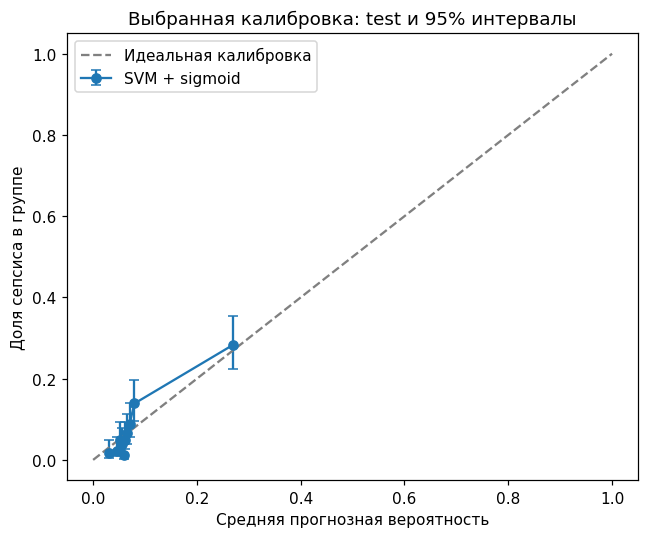

In [52]:
def reliability_table(y_true,probability):
    table = pd.DataFrame({'y':np.asarray(y_true),'p':np.asarray(probability)})
    table['группа'] = (pd.qcut(table.p,q=10,duplicates='drop')
        if table.p.nunique()>1 else 'все')
    grouped = table.groupby('группа',observed=True).agg(
        n=('y','size'),cases=('y','sum'),p_mean=('p','mean'))
    grouped['observed'] = grouped.cases/grouped.n
    z = 1.96
    denominator = 1+z*z/grouped.n
    center = (grouped.observed+z*z/(2*grouped.n))/denominator
    radius = z*np.sqrt(grouped.observed*(1-grouped.observed)/grouped.n
        +z*z/(4*grouped.n**2))/denominator
    grouped['95% lower'],grouped['95% upper'] = center-radius,center+radius
    return grouped

def probability_metrics(y_true,probability):
    rel = reliability_table(y_true,probability)
    return {'Brier':brier_score_loss(y_true,probability),
        'Log loss':log_loss(y_true,probability,labels=[0,1]),
        'ROC-AUC':roc_auc_score(y_true,probability),
        'AP':average_precision_score(y_true,probability),
        'средний риск':np.mean(probability),'фактическая доля':np.mean(y_true),
        'ECE':np.average(abs(rel.p_mean-rel.observed),weights=rel.n)}

calibrators, calibration_rows = {}, []
for method in ['sigmoid','isotonic']:
    calibrated = CalibratedClassifierCV(FrozenEstimator(core_svm),method=method)
    calibrated.fit(X_cal,y_cal)  # core_svm не переобучается на этих пациентах.
    values = probability_metrics(y_policy,calibrated.predict_proba(X_policy)[:,1])
    calibration_rows.append({'метод':method,**values})
    calibrators[method] = calibrated
calibration_validation = pd.DataFrame(calibration_rows).set_index('метод')
calibration_method = calibration_validation.sort_values(['Brier','Log loss']).index[0]
risk_model = calibrators[calibration_method]
p_policy = risk_model.predict_proba(X_policy)[:,1]
p_risk_test = risk_model.predict_proba(X_test)[:,1]
display(calibration_validation.round(4))
print('Калибровка выбрана по policy_validation:',calibration_method)

probability_test_rows = []
for name,prob in [('Sigmoid',calibrators['sigmoid'].predict_proba(X_test)[:,1]),
    ('Isotonic',calibrators['isotonic'].predict_proba(X_test)[:,1]),
    ('NB, прежняя модель',p_test),('Постоянный риск',np.full(len(y_test),y_model.mean()))]:
    probability_test_rows.append({'метод':name,**probability_metrics(y_test,prob)})
display(pd.DataFrame(probability_test_rows).set_index('метод').round(4))
rel_test = reliability_table(y_test,p_risk_test)
display(rel_test.round(4))
fig,ax = plt.subplots(figsize=(6,5))
ax.errorbar(rel_test.p_mean,rel_test.observed,
    yerr=[rel_test.observed-rel_test['95% lower'],rel_test['95% upper']-rel_test.observed],
    fmt='o-',capsize=3,label=f'SVM + {calibration_method}')
ax.plot([0,1],[0,1],'--',color='gray',label='Идеальная калибровка')
ax.set(xlabel='Средняя прогнозная вероятность',ylabel='Доля сепсиса в группе',
       title='Выбранная калибровка: test и 95% интервалы')
ax.legend()
plt.tight_layout()
plt.show()

## 8. Порог принятия решения: деньги и места

В упрощённой функции потерь задания правильные решения имеют нулевую дополнительную стоимость. Тогда для калиброванного риска p: потери при запуске — `(1−p)·20 000`, при отказе — `p·500 000`. Выгоднее запускать при **p ≥ 3,85%**. Это учитывает отношение стоимостей ошибок 1:25 и не использует необоснованный порог 0,5.

Однако низкий денежный порог может дать больше 30 кандидатов. Рассчитываем на policy_validation:

1. Теоретический порог 3,85% без ограничения мест.
2. Эмпирический порог с минимальными потерями FP/FN без ограничения мест.
3. Эмпирический порог с минимальными потерями при **средней** доле запусков не выше 30/200=15%.

Третий порог не гарантирует ежедневный лимит: доля пациентов может измениться. Поэтому отдельно рассматриваем **очередь по риску**: кандидаты имеют риск ≥3,85%, а при дефиците мест первые — пациенты с наибольшим риском. По заданной функции потерь ожидаемый выигрыш действия растёт с p, поэтому такой порядок обоснован ценами ошибок. Если положительный ожидаемый выигрыш есть менее чем у 30 пациентов, искусственно заполнять все места не нужно.

Порог и метод калибровки выбираются без test. После выбора не переобучаем ни исходную модель, ни калибратор: это могло бы изменить смысл уже выбранного порога.

In [53]:
# функция порогов
def threshold_table(y_true,probability):
    thresholds = np.unique(np.r_[0.,probability,np.nextafter(1.,2.)])
    rows = []
    for threshold in thresholds:
        decision = np.asarray(probability)>=threshold
        values = score_metrics(y_true,probability,decision)
        rows.append({'порог':threshold,**values,
            'доля запусков':values['Тревог']/len(y_true),
            'мест/200':FLOW*values['Тревог']/len(y_true),
            'потери ₽/200':FLOW*values['Условные потери ₽']/len(y_true)})
    return pd.DataFrame(rows)

thresholds_validation = threshold_table(y_policy,p_policy)
unrestricted = thresholds_validation.sort_values(['Условные потери ₽','Тревог']).iloc[0]
feasible = thresholds_validation[thresholds_validation['доля запусков']<=CAPACITY/FLOW]
restricted = feasible.sort_values(['Условные потери ₽','Тревог']).iloc[0]
threshold_unrestricted = float(unrestricted['порог'])
threshold_restricted = float(restricted['порог'])
chosen_thresholds = {'Денежный порог 3,85%':economic_threshold,
    'Минимум потерь на validation':threshold_unrestricted,
    'Минимум потерь при ≤30 мест/200 на validation':threshold_restricted}
threshold_report = []
for name,threshold in chosen_thresholds.items():
    for split,yy,prob in [('validation',y_policy,p_policy),('test',y_test,p_risk_test)]:
        values = score_metrics(yy,prob,prob>=threshold)
        threshold_report.append({'правило':name,'выборка':split,'порог':threshold,**values,
            'мест/200':FLOW*values['Тревог']/len(yy),
            'потери ₽/200':FLOW*values['Условные потери ₽']/len(yy)})

# Визуализация всех параметров и метрик
display(pd.DataFrame(threshold_report).round(4))
print('Порог с ограничением средней нагрузки:',round(threshold_restricted,4))
print('Это проверенный на validation кандидат для фиксированного порога, а не гарантия суточного лимита.')

,правило,выборка,порог,ROC-AUC,AP,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,TP,FP,FN,TN,Тревог,Условные потери ₽,мест/200,потери ₽/200
0,"Денежный порог 3,85%",validation,0.0385,0.7691,0.3923,0.1757,0.5329,0.0816,0.9545,0.1113,0.1503,0.3040,105,1182,5,148,1287,26140000,178.7500,3.630556e+06
1,"Денежный порог 3,85%",test,0.0385,0.7589,0.3164,0.1622,0.5397,0.0828,0.9855,0.0939,0.1528,0.3099,136,1506,2,156,1642,31120000,182.4444,3.457778e+06
2,Минимум потерь на validation,validation,0.0595,0.7691,0.3923,0.5292,0.6701,0.1223,0.8364,0.5038,0.2135,0.3859,92,660,18,670,752,22200000,104.4444,3.083333e+06
3,Минимум потерь на validation,test,0.0595,0.7589,0.3164,0.5139,0.6570,0.1181,0.8261,0.4880,0.2067,0.3757,114,851,24,811,965,29020000,107.2222,3.224444e+06
4,Минимум потерь при ≤30 мест/200 на validation,validation,0.0790,0.7691,0.3923,0.8590,0.7027,0.2754,0.5182,0.8872,0.3596,0.4405,57,150,53,1180,207,29500000,28.7500,4.097222e+06
5,Минимум потерь при ≤30 мест/200 на validation,test,0.0790,0.7589,0.3164,0.8450,0.6802,0.2436,0.4855,0.8748,0.3245,0.4051,67,208,71,1454,275,39660000,30.5556,4.406667e+06


Порог с ограничением средней нагрузки: 0.079
Это проверенный на validation кандидат для фиксированного порога, а не гарантия суточного лимита.


### 8.1. Проверка политики с жёстким ограничением мест

В CSV нет дат. Для расчёта ресурса случайно распределяем 1800 test-пациентов на девять **условных** групп по 200, без использования метки sepsis при формировании групп или приоритета. В каждой группе берём до 30 пациентов с риском ≥3,85%, в порядке убывания риска; совпадения разрешаем по patient_id.

Это ретроспективная оценка очереди, которая видит весь набор кандидатов группы. Она не моделирует поступление за минуты, освобождение занятых коек или длительность лечения. В реальном отделении приоритет должен применяться к текущим доступным кандидатам; для подтверждения качества такой работы необходимы время поступления и состояние коек. Здесь протокол и место считаются одним действием, как условное допущение задачи.

Дополнительно повторяем случайные группировки: это проверка чувствительности расчёта к составу условных дней, а не доверительный интервал эффективности лечения.

In [54]:
# адаптация к условиям
def decisions_with_capacity(probability,index,threshold,capacity=CAPACITY,seed=SEED):
    prob = np.asarray(probability)
    ids = df.loc[index,'patient_id'].to_numpy()
    order = np.random.default_rng(seed).permutation(len(prob))
    decision = np.zeros(len(prob),dtype=int)
    days = []
    for start in range(0,len(prob),FLOW):
        positions = order[start:start+FLOW]
        eligible = positions[prob[positions]>=threshold]
        priority = sorted(eligible,key=lambda pos:(-prob[pos],ids[pos]))
        selected = priority[:capacity]
        decision[selected] = 1
        days.append({'группа':start//FLOW+1,'пациентов':len(positions),
            'кандидатов':len(eligible),'занято мест':len(selected),
            'отложено из-за лимита':len(eligible)-len(selected)})
    return decision,pd.DataFrame(days)

capacity_test_decision,day_load = decisions_with_capacity(
    p_risk_test,X_test.index,economic_threshold)
assert day_load['занято мест'].le(CAPACITY).all()
capacity_metrics = score_metrics(y_test,p_risk_test,capacity_test_decision)
display(day_load)
display(pd.DataFrame([capacity_metrics]).round(4))
grouping_results = []
for seed in range(SEED,SEED+300):
    decisions,_ = decisions_with_capacity(p_risk_test,X_test.index,economic_threshold,seed=seed)
    values = score_metrics(y_test,p_risk_test,decisions)
    grouping_results.append({'Recall':values['Recall'],'найдено/200':values['TP']*FLOW/len(y_test),
        'мест/200':values['Тревог']*FLOW/len(y_test),
        'потери ₽/200':values['Условные потери ₽']*FLOW/len(y_test)})
grouping_summary = pd.DataFrame(grouping_results).agg(['mean','min','max'])
display(grouping_summary.round(3))

,группа,пациентов,кандидатов,занято мест,отложено из-за лимита
0,1,200,187,30,157
1,2,200,178,30,148
2,3,200,183,30,153
3,4,200,182,30,152
4,5,200,181,30,151
5,6,200,187,30,157
6,7,200,180,30,150
7,8,200,183,30,153
8,9,200,181,30,151


,ROC-AUC,AP,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,F2,TP,FP,FN,TN,Тревог,Условные потери ₽
0,0.7589,0.3164,0.8456,0.6738,0.2407,0.471,0.8767,0.3186,0.3954,65,205,73,1457,270,40600000


,Recall,найдено/200,мест/200,потери ₽/200
mean,0.476,7.291,30.0,4475288.889
min,0.442,6.778,30.0,4222222.222
max,0.507,7.778,30.0,4742222.222


## 9. Заключение для отделения
### 9.1. Сколько мест требуется для заданного уровня выявления

Уровень «нужного выявления» в задании не указан. Поэтому заранее рассматриваем **50%, 70%, 80%, 90% recall**. Для каждого выбираем на policy_validation порог, который достигает цели с наименьшим числом запусков. Эти пороги фиксируем, затем измеряем **фактически достигнутый** recall и нагрузку на test.

Таблица не подбирает пороги по test и не утверждает, что цель обязательно достигнется на новых пациентах. Число мест — ожидаемые запуски на 200 обращений при сходном составе потока и принятом допущении «один запуск — одно место». Полная оценка необходимого коечного фонда потребует длительности пребывания. Если при выбранном пороге нужно существенно больше 30 мест, данный уровень recall и текущий ресурс в этой модели несовместимы.

In [55]:
target_rows = []
for target in [.50,.70,.80,.90]:
    candidates = thresholds_validation[thresholds_validation.Recall>=target]
    selected = candidates.sort_values(['Тревог','Условные потери ₽']).iloc[0]
    threshold = float(selected['порог'])
    observed = score_metrics(y_test,p_risk_test,p_risk_test>=threshold)
    beds_test = observed['Тревог']*FLOW/len(y_test)
    target_rows.append({'цель recall на validation':target,'порог':threshold,
        'recall validation':selected.Recall,'мест/200 validation':selected['мест/200'],
        'recall test':observed['Recall'],'мест/200 test':beds_test,
        'мест сверх 30 на test':max(0.,beds_test-CAPACITY),
        'найдено сепсиса/200 test':observed['TP']*FLOW/len(y_test),
        'ложных тревог/200 test':observed['FP']*FLOW/len(y_test),
        'пропущено сепсиса/200 test':observed['FN']*FLOW/len(y_test),
        'потери ₽/200 test':observed['Условные потери ₽']*FLOW/len(y_test)})
target_report = pd.DataFrame(target_rows)
display(target_report.round(3))

policy_decisions = {'Нет запусков: статистический ориентир':np.zeros(len(y_test),dtype=int),
    'Денежный порог без ограничения':p_risk_test>=economic_threshold,
    'Фиксированный порог по validation':p_risk_test>=threshold_restricted,
    'Денежный порог + очередь до 30':capacity_test_decision}
department_rows = []
for name,decision in policy_decisions.items():
    values = score_metrics(y_test,p_risk_test,decision)
    department_rows.append({'политика':name,'Recall':values['Recall'],'Precision':values['Precision'],
        'найдено/200':values['TP']*FLOW/len(y_test),
        'ложных тревог/200':values['FP']*FLOW/len(y_test),
        'пропущено/200':values['FN']*FLOW/len(y_test),
        'мест/200':values['Тревог']*FLOW/len(y_test),
        'потери ₽/200':values['Условные потери ₽']*FLOW/len(y_test)})
department_report = pd.DataFrame(department_rows).set_index('политика')
display(department_report.round(3))

,цель recall на validation,порог,recall validation,мест/200 validation,recall test,мест/200 test,мест сверх 30 на test,найдено сепсиса/200 test,ложных тревог/200 test,пропущено сепсиса/200 test,потери ₽/200 test
0,0.5,0.080,0.5,27.917,0.478,29.222,0.000,7.333,21.889,8.000,4437777.778
1,0.7,0.067,0.7,62.778,0.674,63.556,33.556,10.333,53.222,5.000,3564444.444
2,0.8,0.060,0.8,98.750,0.819,102.778,72.778,12.556,90.222,2.778,3193333.333
3,0.9,0.052,0.9,143.750,0.920,149.000,119.000,14.111,134.889,1.222,3308888.889


,Recall,Precision,найдено/200,ложных тревог/200,пропущено/200,мест/200,потери ₽/200
политика,,,,,,,
Нет запусков: статистический ориентир,0.000,0.000,0.000,0.000,15.333,0.000,7666666.667
Денежный порог без ограничения,0.986,0.083,15.111,167.333,0.222,182.444,3457777.778
Фиксированный порог по validation,0.486,0.244,7.444,23.111,7.889,30.556,4406666.667
Денежный порог + очередь до 30,0.471,0.241,7.222,22.778,8.111,30.000,4511111.111


### 9.2. Численное заключение

«Нет запусков» — только статистический ориентир. Действующая политика врача в датасете не записана, поэтому нельзя утверждать преимущество над реальной работой отделения. FP·20 000 + FN·500 000 — условная оценка потерь; она не включает стоимость правильного лечения, полную занятость коек или измеренный эффект лечения. «Находим» означает положительную метку sepsis у выбранного пациента; предотвращённые осложнения и спасённые жизни здесь не измерены.

Следующая ячейка формирует заключение из фактически полученных чисел.

In [56]:
main_policy = department_report.loc['Денежный порог + очередь до 30']
reference_policy = department_report.loc['Нет запусков: статистический ориентир']
selected_probability_metrics = probability_metrics(y_test,p_risk_test)
print('Предложение для ретроспективного пилота: использовать калиброванный SVM как средство приоритизации.')
print('Калибровка:',calibration_method,'| Параметры:',core_search.best_params_,
      '| Лактат:',method_labels[core_method])
print(f'На test: Brier={selected_probability_metrics["Brier"]:.4f}, '
      f'log loss={selected_probability_metrics["Log loss"]:.4f}, '
      f'ECE={selected_probability_metrics["ECE"]:.4f}.')
print(f'Средний прогноз риска {p_risk_test.mean():.2%}; фактическая частота сепсиса {y_test.mean():.2%}.')
print(f'Денежный порог кандидата: {economic_threshold:.2%}. '
      f'При дефиците мест — очередь по риску с лимитом {CAPACITY} на условную группу {FLOW}.')
print(f'При такой политике на 200 обращений: выявляем {main_policy["найдено/200"]:.1f} случаев '
      f'(recall {main_policy["Recall"]:.1%}), ложных тревог {main_policy["ложных тревог/200"]:.1f}, '
      f'пропускаем {main_policy["пропущено/200"]:.1f}.')
print(f'Средняя нагрузка {main_policy["мест/200"]:.1f} мест; '
      f'условные потери {main_policy["потери ₽/200"]:,.0f} ₽ на 200 обращений.')
print(f'Снижение расчётных потерь против статистического ориентира «нет запусков»: '
      f'{reference_policy["потери ₽/200"]-main_policy["потери ₽/200"]:,.0f} ₽ на 200 обращений.')
print(f'Фиксированный порог, выбранный при средней вместимости: {threshold_restricted:.2%}; '
      'суточный лимит он самостоятельно не гарантирует.')
for _,row in target_report.iterrows():
    print(f'Для цели recall {row["цель recall на validation"]:.0%} на validation: '
          f'порог {row["порог"]:.2%}; на test достигнуто {row["recall test"]:.1%}, '
          f'потребность {row["мест/200 test"]:.1f} мест на 200 обращений.')
print('Вероятности проверены на группах; доверять каждому числу как точной индивидуальной вероятности нельзя.')
print('Граница запуска протокола в реальной больнице требует временной проверки, учёта освобождения коек '
      'и клинической оценки. Ретроспективная очередь видит всех кандидатов условного дня заранее.')

Предложение для ретроспективного пилота: использовать калиброванный SVM как средство приоритизации.
Калибровка: sigmoid | Параметры: {'svc': SVC(cache_size=256, random_state=42), 'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'} | Лактат: Медиана
На test: Brier=0.0640, log loss=0.2408, ECE=0.0208.
Средний прогноз риска 7.90%; фактическая частота сепсиса 7.67%.
Денежный порог кандидата: 3.85%. При дефиците мест — очередь по риску с лимитом 30 на условную группу 200.
При такой политике на 200 обращений: выявляем 7.2 случаев (recall 47.1%), ложных тревог 22.8, пропускаем 8.1.
Средняя нагрузка 30.0 мест; условные потери 4,511,111 ₽ на 200 обращений.
Снижение расчётных потерь против статистического ориентира «нет запусков»: 3,155,556 ₽ на 200 обращений.
Фиксированный порог, выбранный при средней вместимости: 7.90%; суточный лимит он самостоятельно не гарантирует.
Для цели recall 50% на validation: порог 7.99%; на test достигнуто 47.8%, потребность 29.2 мест на 200 обращений.
Для цел

### Итог расчёта

**Вероятности.** На независимой от обучения модели validation выбрана sigmoid-калибровка. Новая модель для этих пунктов имеет RBF, C=1, gamma=scale и медианную импутацию лактата; отличие от C=10 в пункте 6 связано с повторным подбором на отдельном model_train. На test Brier = 0,064 против 0,071 у постоянного риска и 0,145 у прежнего NB; log loss = 0,241. Средний риск 7,90% близок к наблюдаемой частоте 7,67%. Однако кривая и таблица групп показывают локальные расхождения, особенно в группах около 6–8% риска. Можно использовать вероятности как приближённые групповые оценки, но нельзя утверждать, что калибровка идеальна или что каждое индивидуальное число точно.

**Порог.** 3,85% — теоретическая денежная граница при заданных потерях и верных вероятностях. Без ограничения мест она даёт около 182 кандидатов на 200 обращений. На policy_validation денежный минимум достигается около 5,95%; минимум потерь при средней вместимости не выше 30 мест — около 7,90%. Последний порог на test даёт уже 30,6 запусков/200, что подтверждает: фиксированный порог сам по себе не гарантирует ежедневный лимит.

**Ресурсная политика для учебного пилота:** кандидат при риске ≥3,85%; при превышении ресурса — приоритет по убыванию риска, до 30 мест в условной группе из 200 обращений. В фиксированном ретроспективном прогоне найдено 65 из 138 случаев (47,1%), ложных тревог 205, пропусков 73; на 200 обращений это примерно 7,2 выявленных случая, 22,8 ложной тревоги и 8,1 пропуска при 30 местах. Условные потери — 4,51 млн ₽/200. При 300 случайных группировках средний recall около 47,6%, диапазон 44,2–50,7%; это вариация сценария группировки, а не доверительный интервал лечебной эффективности.

**Потребность для более высокого выявления:**

| Цель на validation | Recall, достигнутый на test | Запусков/мест на 200 обращений в среднем |
|---|---:|---:|
| 50% | 47,8% | 29,2 |
| 70% | 67,4% | 63,6 |
| 80% | 81,9% | 102,8 |
| 90% | 92,0% | 149,0 |

При текущей модели 30 мест обеспечивают лишь примерно половину выявления в данном ретроспективном сценарии. Цель около 80% потребовала бы примерно 103 запуска/200, преимущественно за счёт роста ложных тревог. Улучшение модели и разграничение протокола, дополнительного наблюдения и занятия койки могут изменить этот компромисс, но их эффект здесь не рассчитан.

Расчётные потери учитывают только FP/FN; выявленные случаи не равны предотвращённым осложнениям. Без дат, длительности лечения и истории свободных мест результат нельзя превратить в точный коечный график. Ретроспективная очередь видит всю условную группу заранее, поэтому подтверждение работы при поступлении в реальном времени остаётся отдельной задачей. Текстовые числа относятся к приложенному файлу; при смене данных ориентируйтесь на программные таблицы выше.

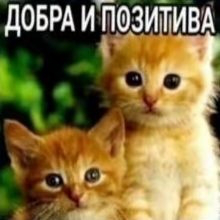

In [59]:
from PIL import Image
img = Image.open("dobra.jpg")
# спасибо, всем:
img